![imagen](./img/ejercicios.png)

# INFORMACIÓN DEL PROYECTO

### TÍTULO

In [ ]:
#Escribe el título del proyecto en Markdown
titulo = "Análisis de condiciones (meteorológicas) óptimas en lanzamiento de cohetes"

### TEMA

In [ ]:
# Describe brevemente el tema del proyecto en Markdown
tema = "Determinar un umbral de viento óptimo para lanzar o qué parámetros habría que modificar en cada caso (paracaídas, etc) " \
"DDeterminar por estación del año lugar óptimo donde lanzar"
#sacar coeficientes de estabilidad, evaluar los outliers
# radio de dispersión a partir de x e y
#velocidad del viento, frente a desviación aterrizaje, fijar el umbral con la retricción
#heatmap de viento, presión, masa, cd, apogeo, tiempo de vuelo
# buscar explicación correlaciones como temperatura y velocidad de aterrizaje.

### HIPÓTESIS

Define aquí lo que será la hipótesis de tu proyecto.
Deberás tener más de una, pero tu proyecto lo harás teniendo una principal hipótesis.

In [ ]:
# Escribe tu hipótesis principal en Markdown
hipotesis_1 = "Los días más calurosos (verano) reducen la densidad del aire, lo que provoca una caída medible en la velocidad_salida_guia y en la presión dinámica (max_q). Esto hace que los vuelos en verano sean estadísticamente más propensos a la inestabilidad temprana que los de invierno."

In [ ]:
# Escribe más hipótesis si las hubiera en Markdown
# hipotesis_2 = "El cohete mantendrá un apogeo superior a X metros en el 95% de los escenarios climáticos posibles"
# hipotesis_3 = "El ángulo de ataque máximo y el ángulo zenital no crecen de forma lineal con el viento transversal, sino que se disparan exponencialmente cuando la velocidad_salida_guia cae por debajo de un umbral crítico (típicamente ~30 m/s) en presencia de un viento cruzado superior a 5 m/s."
# hipotesis_4 = "El viento en superficie es irrelevante para predecir dónde caerá el cohete. El radio_dispersion está fuertemente correlacionado con el viento_max_mag y el viento sostenido en los niveles de presión superiores (300-500 hPa)"
# hipotesis_5 = "Un retraso en la apertura del paracaídas no altera significativamente el radio de dispersión en días tranquilos, pero tiene un efecto multiplicativo (no aditivo) cuando interactúa con un viento_promedio_mag elevado"
# hipotesis_6 = "Dima, al tener un clima oceánico y orografía montañosa, presentará variaciones de dirección de viento entre niveles de presión (cizalladura) mucho más abruptas que Zaragoza o Jaén. Esto se traducirá en picos de angulo_ataque_maximo sistemáticamente más altos en Dima, haciendo que su margen de seguridad estructural sea el más crítico"
# hipotesis_7 = "Como cada base tiene una elevación distinta respecto al nivel del mar, la presion_superficie inicial cambia. Las bases a mayor altitud tendrán un aire menos denso por defecto, lo que disminuirá el max_q (estrés aerodinámico) pero a costa de un menor margen_estatico_salida_guia"
# hopotesis_8 = "El viento_max_mag (viento en altura) es significativamente más fuerte en EuRoC (Portugal) en octubre que en el resto de ubicaciones en sus meses promedio, empujando el radio_dispersion medio de Portugal muy por encima del de las bases españolas."


## OBTENCIÓN DE LOS DATOS

### DATASETS Y FUENTES ALTERNATIVAS DE DATOS

Incluye aquí una vista del dataset o datasets de los que partirás para poder evaluar tu hipótesis. <br>
También incluye el origen de estos datos y su fuente.

In [15]:
import pandas as pd

# 1. Cargar el dataset en un DataFrame
df_zaragoza = pd.read_csv("dataset_vuelos_zaragoza.csv")

# 2. Contar los nulos por cada columna (mostrando solo las afectadas)
nulos_por_columna = df_zaragoza.isnull().sum()
print("Nulos por columna:\n", nulos_por_columna[nulos_por_columna > 0])

# 3. Contar el impacto real: cuántas filas (vuelos) tienen al menos un nulo
filas_con_nulos = df_zaragoza.isnull().any(axis=1).sum()
print(f"\nTotal de vuelos con datos faltantes: {filas_con_nulos} de {len(df_zaragoza)}")

Nulos por columna:
 Series([], dtype: int64)

Total de vuelos con datos faltantes: 0 de 1200


Muestra mediante un head() los principales datasets con los que vas a trabajar

In [16]:
# Primer dataset
df_zaragoza.columns


Index(['ubicacion', 'fecha_vuelo', 'hora_vuelo', 'estacion', 'archivo_origen',
       'heading', 'inclination', 'viento_superficie_x', 'viento_superficie_y',
       'temperatura_superficie_celsius', 'presion_superficie',
       'viento_promedio_mag', 'viento_max_mag', 'viento_min_mag',
       'direccion_viento_superficie', 'direccion_viento_maximo',
       'masa_seca_real', 'cd_cohete_multiplicador', 'cd_s_paracaidas_real',
       'retraso_apertura_real', 'apogeo', 'velocidad_maxima', 'mach_maximo',
       'velocidad_salida_guia', 'velocidad_aterrizaje',
       'aceleracion_maxima_despegue', 'aceleracion_maxima_apertura',
       'aterrizaje_x', 'aterrizaje_y', 'radio_dispersion',
       'angulo_zenital_apogeo', 'max_q', 'margen_estatico_minimo',
       'margen_estatico_salida_guia', 'angulo_ataque_maximo'],
      dtype='object')

In [27]:
df_zaragoza['cd_cohete_multiplicador']

0       1.2
1       1.2
2       1.2
3       1.2
4       1.2
       ... 
1195    1.2
1196    1.2
1197    1.2
1198    1.2
1199    1.2
Name: cd_cohete_multiplicador, Length: 1200, dtype: float64

In [19]:
df_zaragoza.describe()

,heading,inclination,viento_superficie_x,viento_superficie_y,temperatura_superficie_celsius,presion_superficie,viento_promedio_mag,viento_max_mag,viento_min_mag,direccion_viento_superficie,...,aceleracion_maxima_despegue,aceleracion_maxima_apertura,aterrizaje_x,aterrizaje_y,radio_dispersion,angulo_zenital_apogeo,max_q,margen_estatico_minimo,margen_estatico_salida_guia,angulo_ataque_maximo
count,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,...,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,135.000000,87.75000,1.756259,-1.050788,17.027067,94907.412171,17.154395,28.259794,4.852169,232.771679,...,21.277612,0.988732,2665.951605,-373.719591,4150.308919,7.162015,316800.680103,2.288292,2.397356,17.013798
std,100.665011,0.55925,5.163528,4.702418,8.814899,565.947801,7.020715,10.992299,3.492398,89.334191,...,0.171660,0.004700,2486.920934,2772.031254,1970.408881,3.887003,4541.584827,0.016785,0.017237,15.454696
min,0.000000,87.00000,-13.799934,-13.305703,1.186037,92816.962782,4.003490,8.313967,0.159116,3.083310,...,20.459594,0.980424,-3985.349785,-8153.482887,65.584583,0.197727,305705.608926,2.236582,2.343718,1.612387
25%,67.500000,87.37500,-1.394526,-3.852437,10.354965,94608.530136,11.622116,19.223006,2.028570,136.478892,...,21.198406,0.983725,929.053311,-2415.378285,2764.889964,4.236985,313174.711701,2.277308,2.386059,7.536275
50%,135.000000,87.75000,2.001679,-0.181942,14.972322,94872.242055,16.795357,28.105679,4.119843,265.972326,...,21.315624,0.990919,2972.250915,-414.118989,3965.789027,6.510444,317289.136904,2.288261,2.397347,11.306620
75%,202.500000,88.12500,5.558156,2.516017,24.285487,95192.652021,21.542881,34.519769,7.217418,313.440969,...,21.391886,0.992782,4495.206109,1494.101389,5367.702475,9.619383,319909.458735,2.299852,2.409359,17.829367
max,270.000000,88.50000,13.248974,12.066385,39.438586,96315.308166,42.211251,62.564664,16.789841,354.576677,...,21.632082,0.995450,9838.542499,8356.463421,10829.400327,19.819448,328407.950178,2.342138,2.452819,75.972858


In [20]:
df_zaragoza.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ubicacion                       1200 non-null   object 
 1   fecha_vuelo                     1200 non-null   object 
 2   hora_vuelo                      1200 non-null   object 
 3   estacion                        1200 non-null   object 
 4   archivo_origen                  1200 non-null   object 
 5   heading                         1200 non-null   int64  
 6   inclination                     1200 non-null   float64
 7   viento_superficie_x             1200 non-null   float64
 8   viento_superficie_y             1200 non-null   float64
 9   temperatura_superficie_celsius  1200 non-null   float64
 10  presion_superficie              1200 non-null   float64
 11  viento_promedio_mag             1200 non-null   float64
 12  viento_max_mag                  12

In [21]:
df_zaragoza.head()

,ubicacion,fecha_vuelo,hora_vuelo,estacion,archivo_origen,heading,inclination,viento_superficie_x,viento_superficie_y,temperatura_superficie_celsius,...,aceleracion_maxima_despegue,aceleracion_maxima_apertura,aterrizaje_x,aterrizaje_y,radio_dispersion,angulo_zenital_apogeo,max_q,margen_estatico_minimo,margen_estatico_salida_guia,angulo_ataque_maximo
0,Zaragoza,2019-04-14,09:00,Primavera,env_eda_Zaragoza_2019_04.nc,0,88.0,5.339811,-3.991735,14.161699,...,21.196545,0.993128,4115.323736,-2901.786680,5035.499517,8.313444,318900.828639,2.313537,2.423397,7.231906
1,Zaragoza,2019-04-14,09:00,Primavera,env_eda_Zaragoza_2019_04.nc,90,88.5,5.339811,-3.991735,14.161699,...,21.261516,0.992373,4594.593173,-3571.308392,5819.323849,4.254073,316709.227278,2.255875,2.364173,7.278851
2,Zaragoza,2019-04-14,09:00,Primavera,env_eda_Zaragoza_2019_04.nc,180,87.0,5.339811,-3.991735,14.161699,...,21.324416,0.992333,4255.156869,-5015.535364,6577.382075,4.457149,318042.989813,2.292903,2.402195,7.279972
3,Zaragoza,2019-04-14,09:00,Primavera,env_eda_Zaragoza_2019_04.nc,270,87.5,5.339811,-3.991735,14.161699,...,21.177936,0.993294,3141.619887,-3698.032783,4852.341907,9.231757,319457.226544,2.292863,2.402045,7.220681
4,Zaragoza,2019-04-14,12:00,Primavera,env_eda_Zaragoza_2019_04.nc,0,88.0,5.616702,-4.001260,17.827884,...,21.247797,0.993042,4516.263297,-1929.223290,4911.062682,7.789398,318126.512260,2.306000,2.415645,7.416389


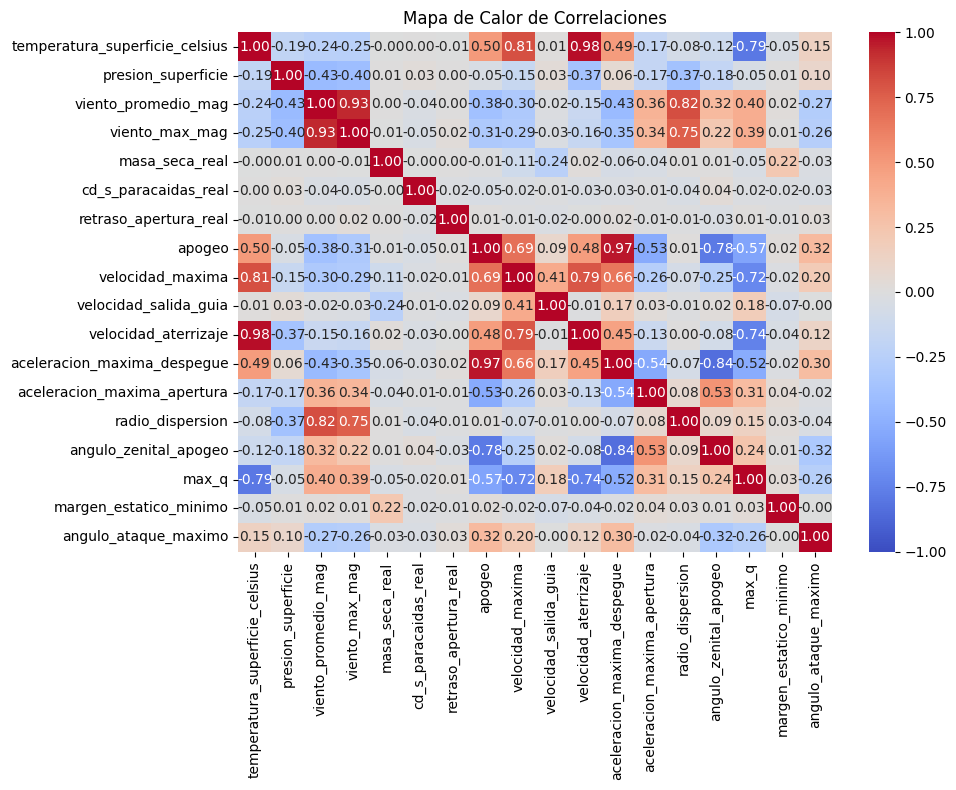

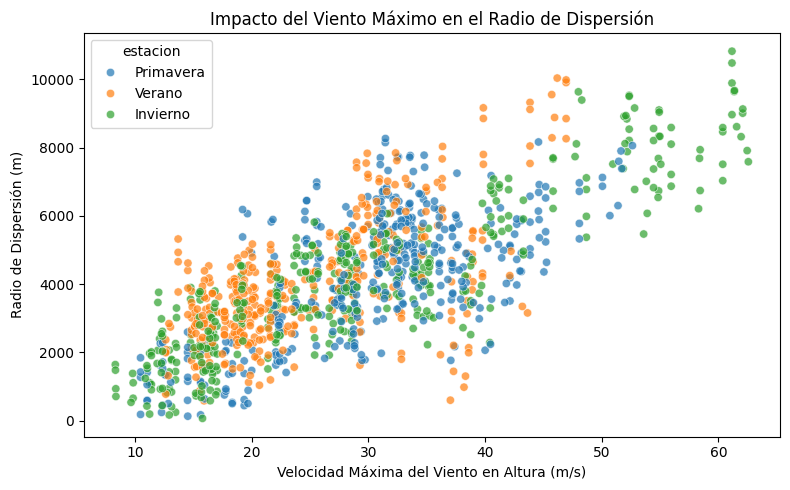

In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el dataset principal
df = pd.read_csv("dataset_vuelos_zaragoza.csv")

# 2. Feature Engineering: Calcular el viento cruzado (0° a 90°)
diferencia_grados = np.abs(df['heading'] - df['direccion_viento_superficie'])
diferencia_grados = np.where(diferencia_grados > 180, 360 - diferencia_grados, diferencia_grados)
# Si es 90, es viento lateral puro. Si es > 90, empieza a ser viento de cola/cara.
df['viento_cruzado_relativo_grados'] = np.where(diferencia_grados > 90, 180 - diferencia_grados, diferencia_grados)

# 3. Matriz de Correlación (Hipótesis globales)
columnas_analisis = [
       'temperatura_superficie_celsius', 'presion_superficie',
       'viento_promedio_mag', 'viento_max_mag',
       'masa_seca_real', 'cd_s_paracaidas_real',
       'retraso_apertura_real', 'apogeo', 'velocidad_maxima',
       'velocidad_salida_guia', 'velocidad_aterrizaje',
       'aceleracion_maxima_despegue', 'aceleracion_maxima_apertura',
        'radio_dispersion',
       'angulo_zenital_apogeo', 'max_q', 'margen_estatico_minimo',
       'angulo_ataque_maximo'
]

correlaciones = df[columnas_analisis].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Mapa de Calor de Correlaciones")
plt.tight_layout()
plt.show()

# 4. Scatterplot específico (Hipótesis 2: Viento Max vs Dispersión)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='viento_max_mag', y='radio_dispersion', hue='estacion', alpha=0.7)
plt.title("Impacto del Viento Máximo en el Radio de Dispersión")
plt.xlabel("Velocidad Máxima del Viento en Altura (m/s)")
plt.ylabel("Radio de Dispersión (m)")
plt.tight_layout()
plt.show()



<Axes: xlabel='rango_viento', ylabel='radio_dispersion'>

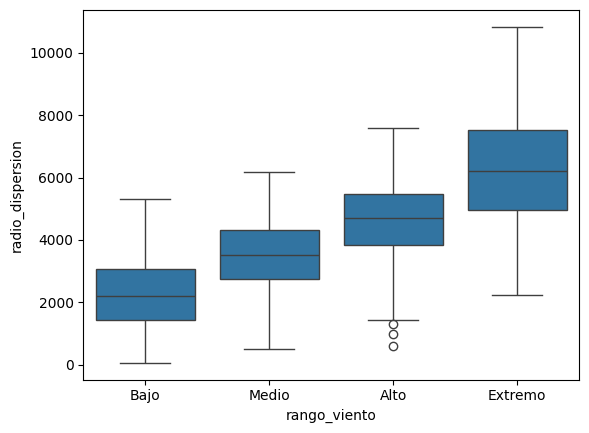

In [33]:
df['rango_viento'] = pd.qcut(df['viento_promedio_mag'], q=4, labels=['Bajo', 'Medio', 'Alto', 'Extremo'])
sns.boxplot(data=df, x='rango_viento', y='radio_dispersion')

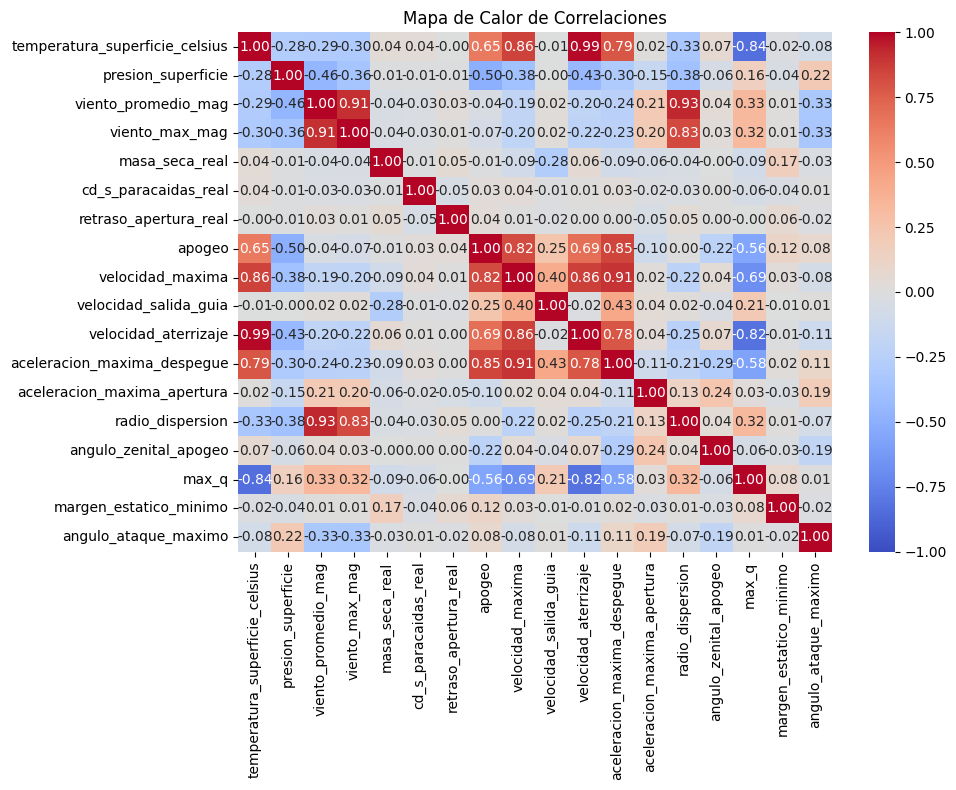

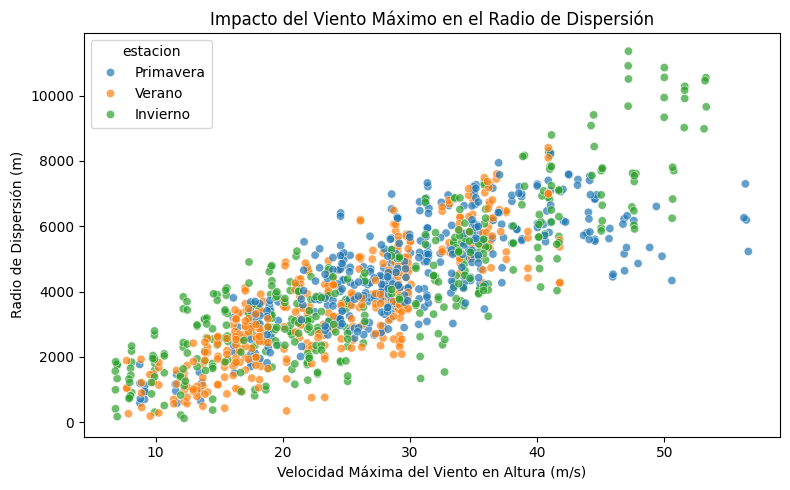

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el dataset principal
df = pd.read_csv("dataset_vuelos_catec.csv")

# 2. Feature Engineering: Calcular el viento cruzado (0° a 90°)
diferencia_grados = np.abs(df['heading'] - df['direccion_viento_superficie'])
diferencia_grados = np.where(diferencia_grados > 180, 360 - diferencia_grados, diferencia_grados)
# Si es 90, es viento lateral puro. Si es > 90, empieza a ser viento de cola/cara.
df['viento_cruzado_relativo_grados'] = np.where(diferencia_grados > 90, 180 - diferencia_grados, diferencia_grados)

# 3. Matriz de Correlación (Hipótesis globales)
columnas_analisis = [
       'temperatura_superficie_celsius', 'presion_superficie',
       'viento_promedio_mag', 'viento_max_mag',
       'masa_seca_real', 'cd_s_paracaidas_real',
       'retraso_apertura_real', 'apogeo', 'velocidad_maxima',
       'velocidad_salida_guia', 'velocidad_aterrizaje',
       'aceleracion_maxima_despegue', 'aceleracion_maxima_apertura',
        'radio_dispersion',
       'angulo_zenital_apogeo', 'max_q', 'margen_estatico_minimo',
       'angulo_ataque_maximo'
]

correlaciones = df[columnas_analisis].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Mapa de Calor de Correlaciones")
plt.tight_layout()
plt.show()

# 4. Scatterplot específico (Hipótesis 2: Viento Max vs Dispersión)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='viento_max_mag', y='radio_dispersion', hue='estacion', alpha=0.7)
plt.title("Impacto del Viento Máximo en el Radio de Dispersión")
plt.xlabel("Velocidad Máxima del Viento en Altura (m/s)")
plt.ylabel("Radio de Dispersión (m)")
plt.tight_layout()
plt.show()



<Axes: xlabel='rango_viento', ylabel='radio_dispersion'>

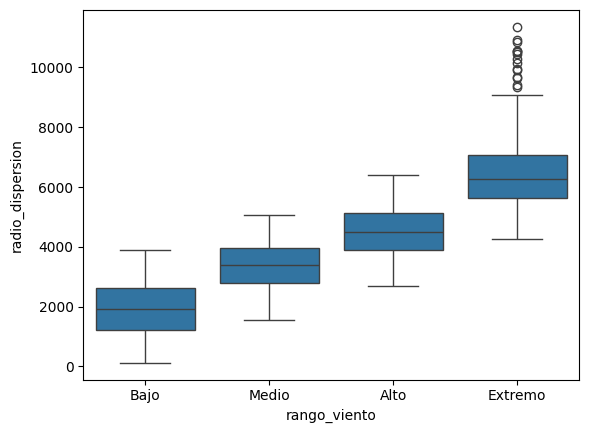

In [38]:
df['rango_viento'] = pd.qcut(df['viento_promedio_mag'], q=4, labels=['Bajo', 'Medio', 'Alto', 'Extremo'])
sns.boxplot(data=df, x='rango_viento', y='radio_dispersion')

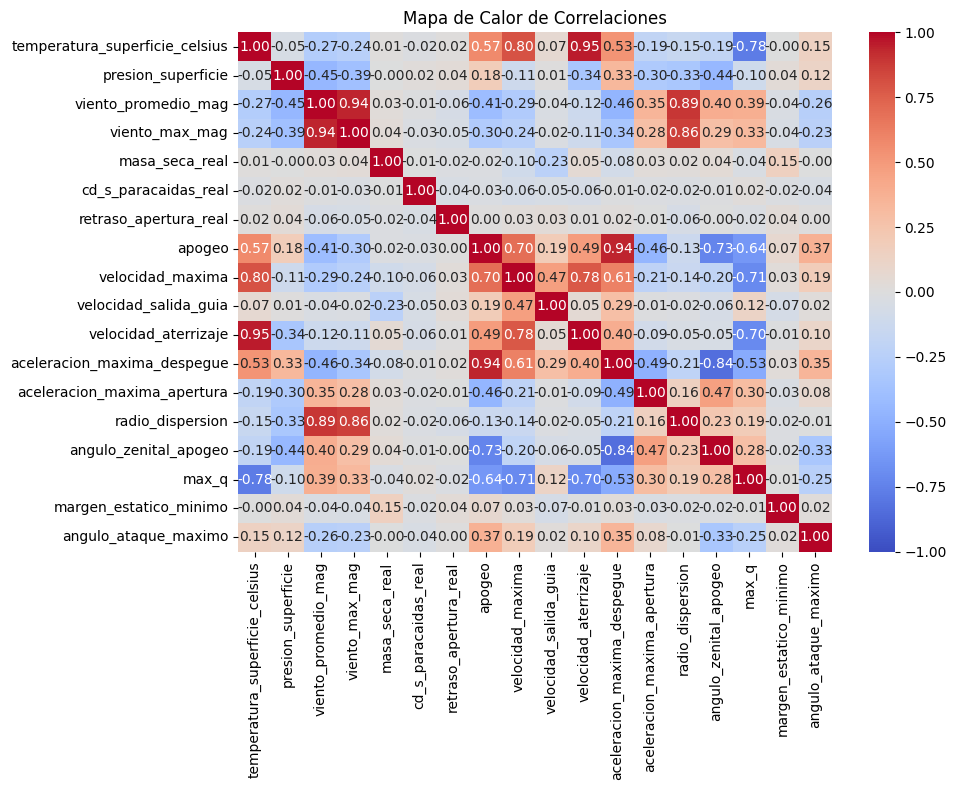

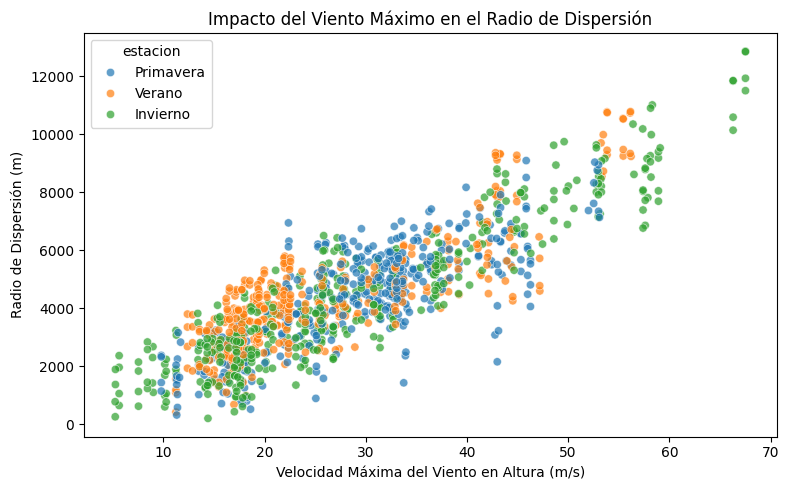

In [42]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el dataset principal
df = pd.read_csv("dataset_vuelos_dima.csv")

# 2. Feature Engineering: Calcular el viento cruzado (0° a 90°)
diferencia_grados = np.abs(df['heading'] - df['direccion_viento_superficie'])
diferencia_grados = np.where(diferencia_grados > 180, 360 - diferencia_grados, diferencia_grados)
# Si es 90, es viento lateral puro. Si es > 90, empieza a ser viento de cola/cara.
df['viento_cruzado_relativo_grados'] = np.where(diferencia_grados > 90, 180 - diferencia_grados, diferencia_grados)

# 3. Matriz de Correlación (Hipótesis globales)
columnas_analisis = [
       'temperatura_superficie_celsius', 'presion_superficie',
       'viento_promedio_mag', 'viento_max_mag',
       'masa_seca_real', 'cd_s_paracaidas_real',
       'retraso_apertura_real', 'apogeo', 'velocidad_maxima',
       'velocidad_salida_guia', 'velocidad_aterrizaje',
       'aceleracion_maxima_despegue', 'aceleracion_maxima_apertura',
        'radio_dispersion',
       'angulo_zenital_apogeo', 'max_q', 'margen_estatico_minimo',
       'angulo_ataque_maximo'
]

correlaciones = df[columnas_analisis].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Mapa de Calor de Correlaciones")
plt.tight_layout()
plt.show()

# 4. Scatterplot específico (Hipótesis 2: Viento Max vs Dispersión)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='viento_max_mag', y='radio_dispersion', hue='estacion', alpha=0.7)
plt.title("Impacto del Viento Máximo en el Radio de Dispersión")
plt.xlabel("Velocidad Máxima del Viento en Altura (m/s)")
plt.ylabel("Radio de Dispersión (m)")
plt.tight_layout()
plt.show()

<Axes: xlabel='rango_viento', ylabel='radio_dispersion'>

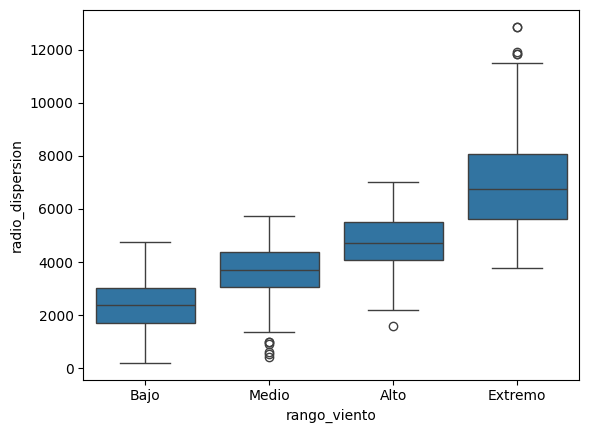

In [40]:
df['rango_viento'] = pd.qcut(df['viento_promedio_mag'], q=4, labels=['Bajo', 'Medio', 'Alto', 'Extremo'])
sns.boxplot(data=df, x='rango_viento', y='radio_dispersion')

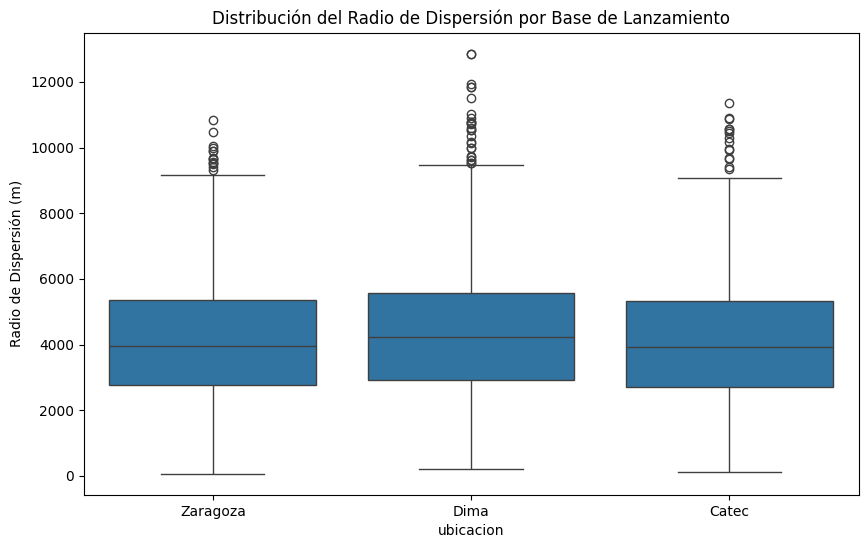

In [47]:

# 1. Cargar y unir todos los datasets (suponiendo que ya generaste los 4)
archivos = [
    "dataset_vuelos_zaragoza.csv", 
    "dataset_vuelos_dima.csv", 
    "dataset_vuelos_catec.csv"
]
df_total = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)


# 3. Visualizar Hipótesis 10: Comparativa de dispersión entre bases
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_total, x='ubicacion', y='radio_dispersion')
plt.title("Distribución del Radio de Dispersión por Base de Lanzamiento")
plt.ylabel("Radio de Dispersión (m)")
plt.show()